# Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Rent.csv / stroke.csv were intermediate files that no longer exist, so build the data from the raw CSVs
raw = pd.read_csv(r'/Users/pawn/Desktop/NTI/House_Rent_Dataset/House_Rent_Dataset.csv')
raw['Posted On'] = pd.to_datetime(raw['Posted On'], errors='coerce')
raw['Posted Year'] = raw['Posted On'].dt.year
raw['Posted Month'] = raw['Posted On'].dt.month
raw = raw.drop(columns=['Posted On', 'Area Locality']).drop_duplicates()
raw['Furnishing Status'] = raw['Furnishing Status'].map({'Unfurnished': 0, 'Semi-Furnished': 1, 'Furnished': 2})
raw['Floor'] = raw['Floor'].astype('category').cat.codes
df = pd.get_dummies(raw, columns=['Area Type', 'City', 'Tenant Preferred', 'Point of Contact'], dtype=int)
df = df.dropna()
df.shape

(4708, 23)

In [3]:
X=df.drop('Rent',axis =1)
y= df[['Rent']]

In [4]:
# Split into Input and Output Elements
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                   test_size= 0.20, random_state=100)

In [5]:
print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (3766, 22)  y_train =  (3766, 1)
X_test  =  (942, 22)  y_test  =  (942, 1)


In [6]:
# MinMaxScaler
from sklearn.preprocessing import MinMaxScaler
my_scaler = MinMaxScaler(feature_range=(0,1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

In [7]:
#!pip install graphviz pydot 
from sklearn.tree import DecisionTreeRegressor, plot_tree

In [8]:
model = DecisionTreeRegressor(
        # Splitting criterion
        criterion='squared_error', 
        #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
        
        # Tree depth
        max_depth=5, # None for unlimited depth

        # Minimum samples to split node
        min_samples_split=10,

        # Minimum samples in leaf
        min_samples_leaf=5,

        # Minimum improvement to split
        min_impurity_decrease=0.01,

        # Pruning parameter
        ccp_alpha=0.1,

        random_state=100
    )

In [9]:
from sklearn.metrics import  r2_score

In [10]:

model.fit(X_train, y_train)

# Predict
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

# ================= Metrics =================

# R2 Score
r2_train = r2_score(y_train, y_pred_train)
r2_test  = r2_score(y_test, y_pred_test)

print(
    r2_train,
    r2_test
)

0.4935603960677306 0.6855442122985522


Plotting Decision Tree Regressor


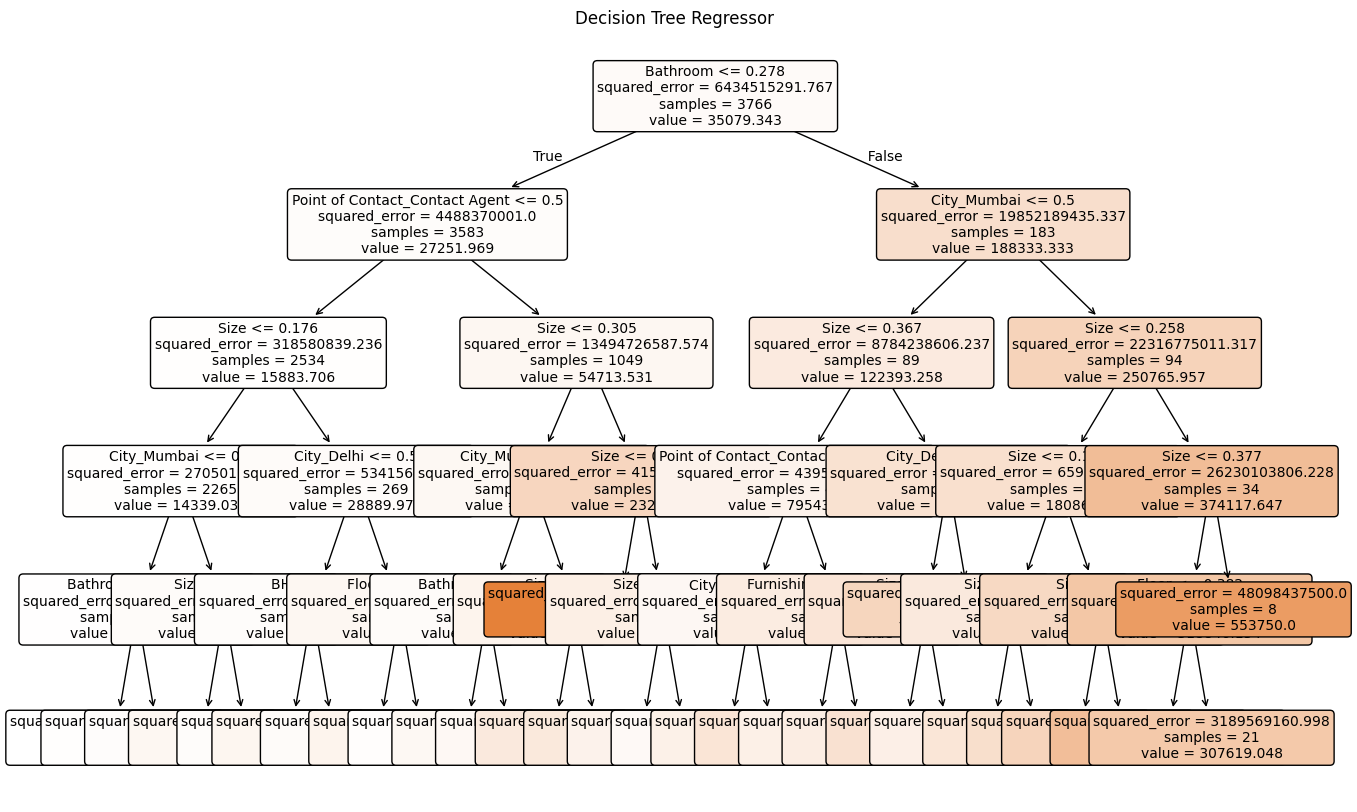

In [11]:
# ======================================================
# Decision Tree Visualization
# ======================================================
print("Plotting Decision Tree Regressor")

plt.figure(figsize=(15,10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Regressor")
plt.show()

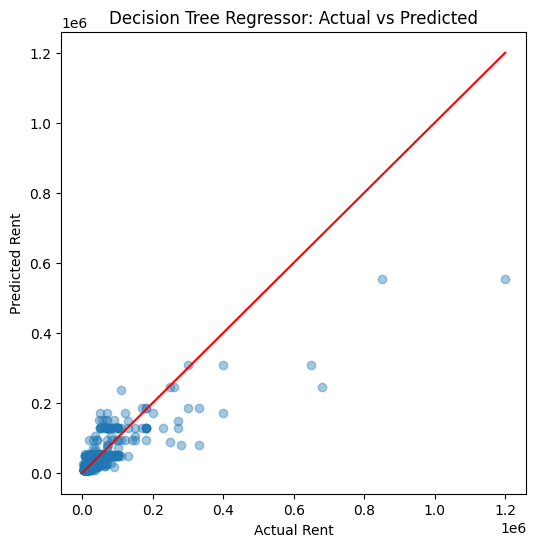

In [12]:
import seaborn as sns
plt.figure(figsize=(6, 6))
plt.scatter(np.ravel(y_test), y_pred_test, alpha=0.4)
lim = [0, float(np.ravel(y_test).max())]
plt.plot(lim, lim, color='red')
plt.xlabel('Actual Rent'); plt.ylabel('Predicted Rent')
plt.title('Decision Tree Regressor: Actual vs Predicted')
plt.show()

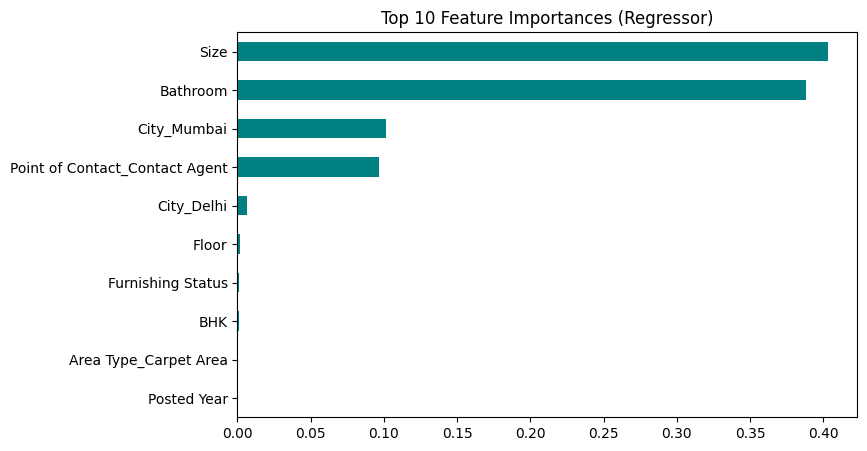

In [13]:
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(10)
plt.figure(figsize=(8, 5))
imp.plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importances (Regressor)')
plt.show()

# Classification 

In [14]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
st = pd.read_csv(r'/Users/pawn/Desktop/NTI/healthcare-dataset-stroke/healthcare-dataset-stroke-data.csv').drop(columns='id')
st['bmi'] = st['bmi'].fillna(st['bmi'].median())
st = pd.get_dummies(st, drop_first=True, dtype=int)
# balance the classes with SMOTE
from imblearn.over_sampling import SMOTE
X_res, y_res = SMOTE(random_state=100).fit_resample(st.drop(columns='stroke'), st['stroke'])
df = pd.concat([X_res, y_res], axis=1)
df.shape

(9722, 17)

In [16]:
X=df.drop('stroke',axis =1)
y= df[['stroke']]

In [17]:
y.value_counts()

stroke
0         4861
1         4861
Name: count, dtype: int64

In [18]:
# Split into Input and Output Elements
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                   test_size= 0.20, random_state=100,stratify=y)

In [19]:
print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (7777, 16)  y_train =  (7777, 1)
X_test  =  (1945, 16)  y_test  =  (1945, 1)


In [20]:
# MinMaxScaler
from sklearn.preprocessing import MinMaxScaler
my_scaler = MinMaxScaler(feature_range=(0,1))
X_train = my_scaler.fit_transform(X_train)
X_test = my_scaler.transform(X_test)

In [21]:
from sklearn.tree import DecisionTreeClassifier,plot_tree


In [22]:
model = DecisionTreeClassifier(

        # Split quality measure
        # "gini"      → Gini impurity (default, fast)
        # "entropy"   → Information gain (ID3 style)
        # "log_loss"  → Similar to entropy but probabilistic
        criterion='gini',

        # Controls randomness for reproducibility
        random_state=100,

        # ================= Pre-Pruning =================
        
        # Maximum depth of the tree
        # None → grow until pure or min_samples reached
        max_depth=10, # None for unlimited depth

        # Minimum samples required to split a node
        min_samples_split=10,

        # Minimum samples required at leaf node
        min_samples_leaf=5,

        # Minimum impurity reduction required to split
        min_impurity_decrease=0.01,

        # ================= Post-Pruning =================
        
        # Cost complexity pruning parameter
        # Higher value → more pruning
        ccp_alpha=0.01
    )



In [23]:
from sklearn.metrics import accuracy_score

In [24]:
# Train model
model.fit(X_train, y_train)

# Predictions
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

# ================= Metrics =================
Acc_Train = accuracy_score(y_train, y_pred_train)
Acc_Test  = accuracy_score(y_test, y_pred_test)

print(
    Acc_Train, 
    Acc_Test,  
)

0.8046804680468047 0.7964010282776349


Decision Tree - Plotting the tree


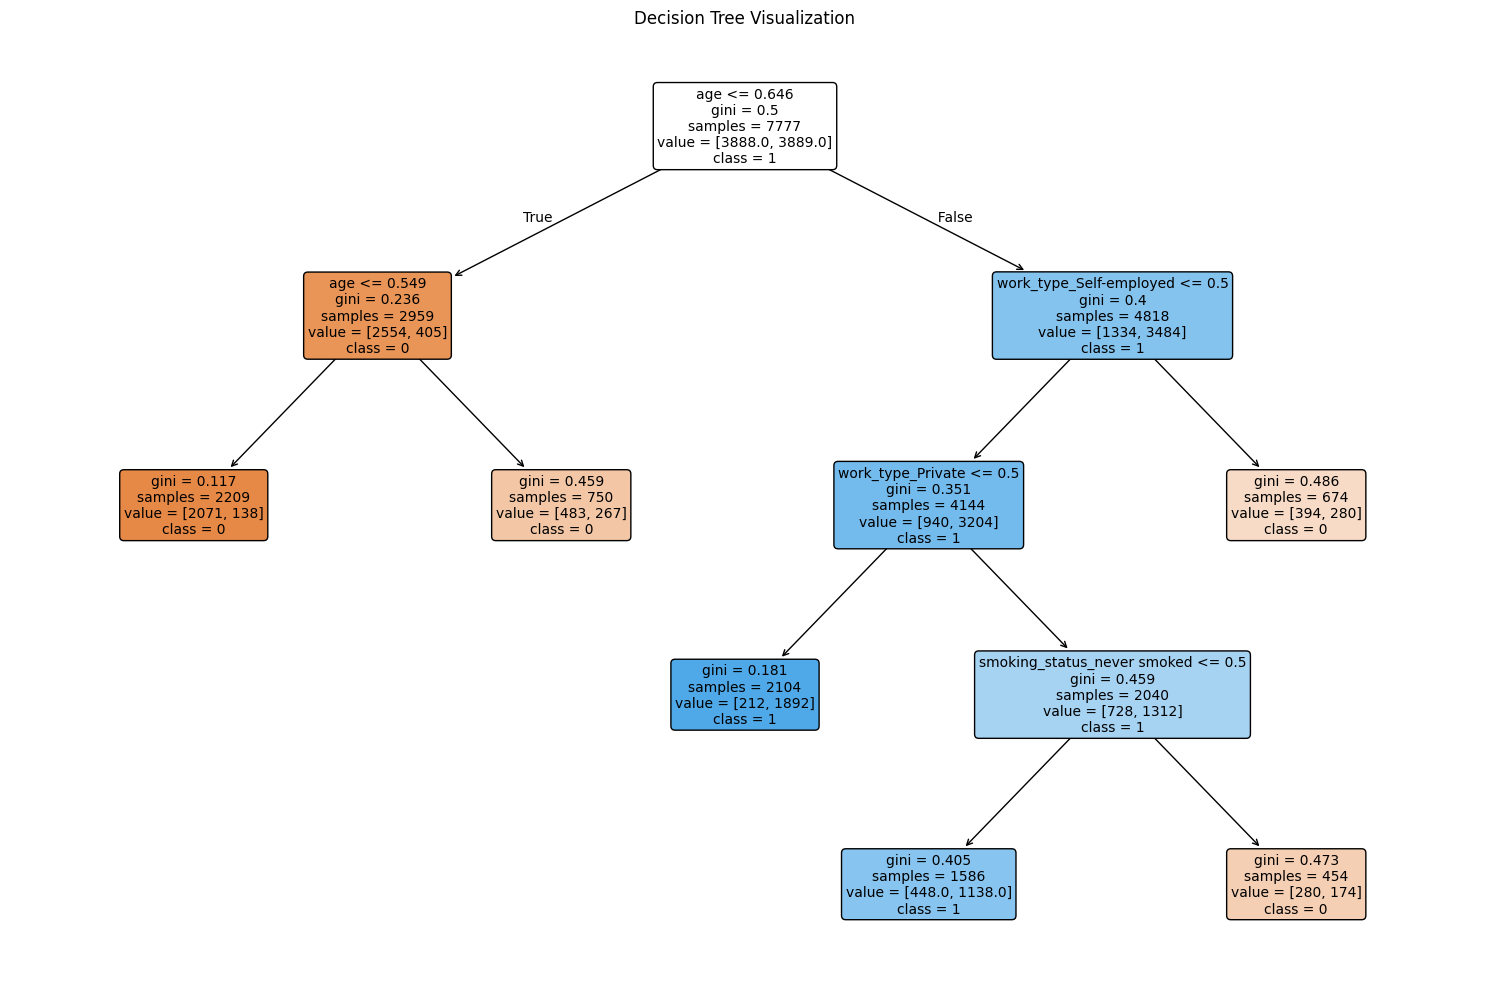

In [25]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

## Classification evaluation

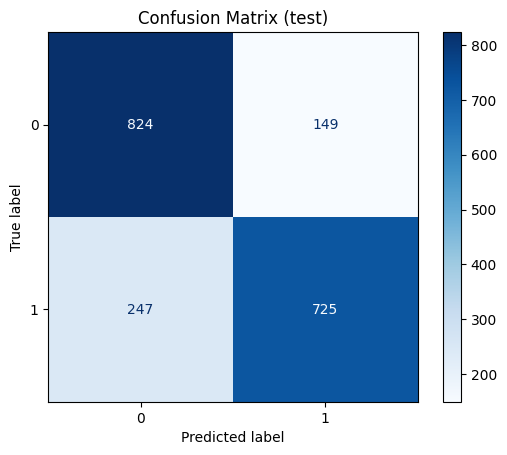

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
plt.title('Confusion Matrix (test)')
plt.show()

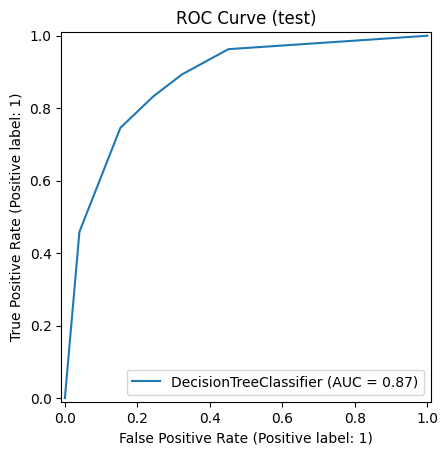

In [27]:
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.title('ROC Curve (test)')
plt.show()

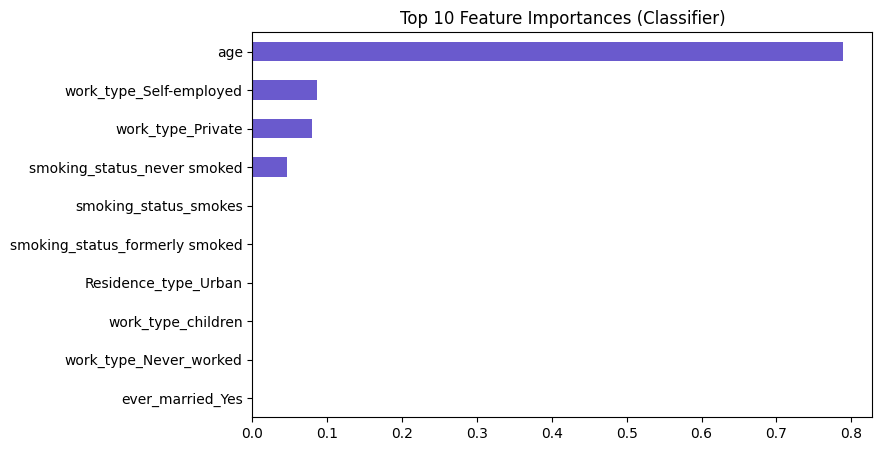

In [28]:
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(10)
plt.figure(figsize=(8, 5))
imp.plot(kind='barh', color='slateblue')
plt.title('Top 10 Feature Importances (Classifier)')
plt.show()